In [1]:
import pandas as pd
import numpy as np

train_df = pd.read_csv("../data/raw/UNSW_NB15_training-set.csv")
test_df = pd.read_csv("../data/raw/UNSW_NB15_testing-set.csv")

print("Training shape:", train_df.shape)
print("Testing shape:", test_df.shape)
print("Number of classes:", train_df["attack_cat"].nunique())

Training shape: (175341, 45)
Testing shape: (82332, 45)
Number of classes: 10


In [2]:
X_train = train_df.drop(columns=["id", "attack_cat", "label"])
X_test = test_df.drop(columns=["id", "attack_cat", "label"])

y_train = train_df["attack_cat"]
y_test = test_df["attack_cat"]

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)
print("Classes:", sorted(y_train.unique()))

X_train: (175341, 42)
X_test: (82332, 42)
y_train: (175341,)
y_test: (82332,)
Classes: ['Analysis', 'Backdoor', 'DoS', 'Exploits', 'Fuzzers', 'Generic', 'Normal', 'Reconnaissance', 'Shellcode', 'Worms']


In [3]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer

categorical_features = ["proto", "service", "state"]

numeric_features = X_train.select_dtypes(include="number").columns.tolist()

numeric_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
    ("numeric", numeric_transformer, numeric_features),
    ("categorical", categorical_transformer, categorical_features)
])

print("Multiclass preprocessing pipeline created successfully!")

Multiclass preprocessing pipeline created successfully!


In [4]:
from sklearn.linear_model import LogisticRegression

multiclass_model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(
        max_iter=1000,
        random_state=42
    ))
])

print("Multiclass baseline model created successfully!")

Multiclass baseline model created successfully!


In [5]:
multiclass_model.fit(X_train, y_train)

print("Multiclass model training completed successfully!")

Multiclass model training completed successfully!


In [6]:
y_pred_multi = multiclass_model.predict(X_test)

print("Total predictions:", len(y_pred_multi))
print("First 10 predictions:", y_pred_multi[:10])

Total predictions: 82332
First 10 predictions: ['Fuzzers' 'Fuzzers' 'Fuzzers' 'Fuzzers' 'Fuzzers' 'Fuzzers' 'Fuzzers'
 'Fuzzers' 'Normal' 'Normal']


In [7]:
from sklearn.metrics import classification_report

print(classification_report(y_test, y_pred_multi, digits=4, zero_division=0))

                precision    recall  f1-score   support

      Analysis     0.0279    0.0148    0.0193       677
      Backdoor     0.0000    0.0000    0.0000       583
           DoS     0.5588    0.0093    0.0183      4089
      Exploits     0.5326    0.7990    0.6391     11132
       Fuzzers     0.2617    0.7356    0.3860      6062
       Generic     0.9914    0.9630    0.9770     18871
        Normal     0.9515    0.6359    0.7623     37000
Reconnaissance     0.4702    0.6845    0.5575      3496
     Shellcode     0.0000    0.0000    0.0000       378
         Worms     0.0000    0.0000    0.0000        44

      accuracy                         0.6983     82332
     macro avg     0.3794    0.3842    0.3360     82332
  weighted avg     0.7941    0.6983    0.7061     82332



In [8]:
pd.Series(y_pred_multi).value_counts().reindex(sorted(y_test.unique()), fill_value=0)

Analysis            359
Backdoor              1
DoS                  68
Exploits          16699
Fuzzers           17041
Generic           18329
Normal            24726
Reconnaissance     5089
Shellcode            16
Worms                 4
Name: count, dtype: int64

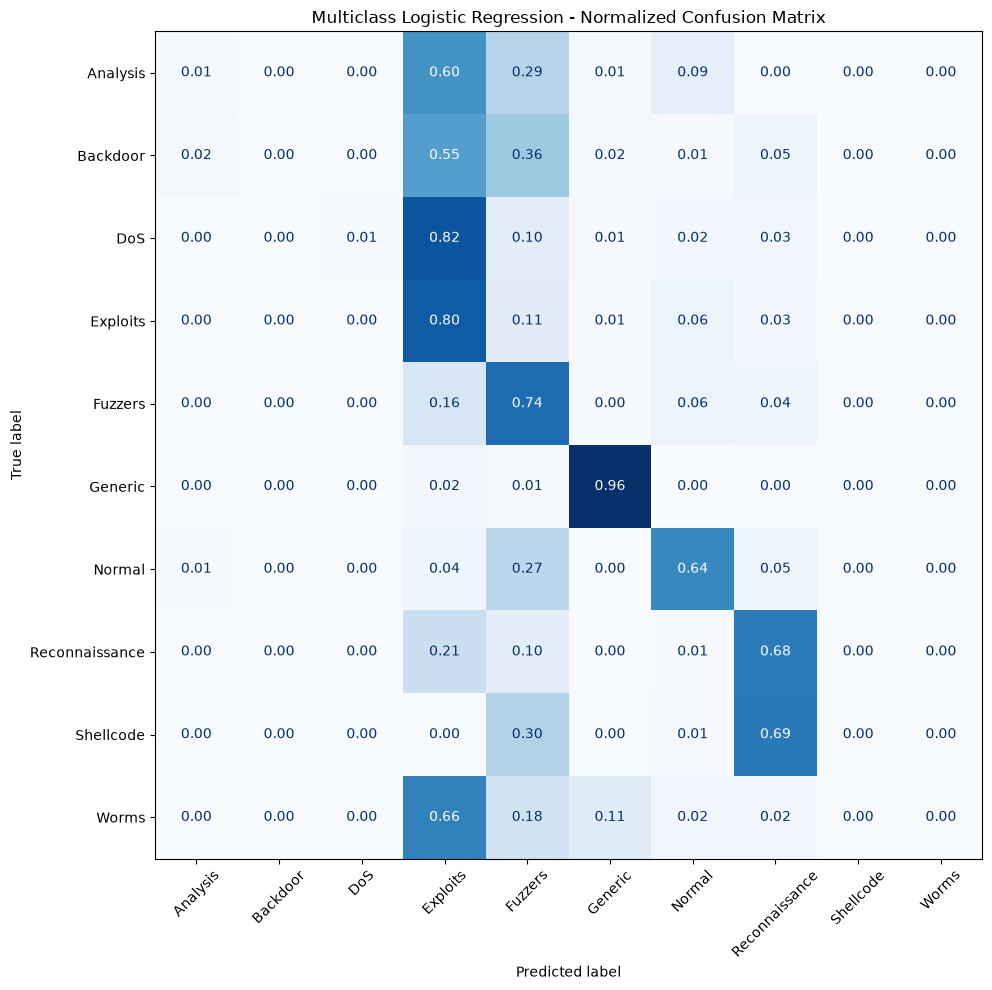

Confusion matrix saved successfully!


In [9]:
from pathlib import Path
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

classes = sorted(y_test.unique())

fig, ax = plt.subplots(figsize=(12, 10))

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred_multi,
    labels=classes,
    normalize="true",
    values_format=".2f",
    cmap="Blues",
    xticks_rotation=45,
    ax=ax,
    colorbar=False
)

ax.set_title("Multiclass Logistic Regression - Normalized Confusion Matrix")

plt.tight_layout()

output_dir = Path("../results/figures")
output_dir.mkdir(parents=True, exist_ok=True)

fig.savefig(
    output_dir / "multiclass_confusion_matrix_normalized.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Confusion matrix saved successfully!")

In [10]:
from pathlib import Path
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    balanced_accuracy_score,
    classification_report
)

output_dir = Path("../results/tables")
output_dir.mkdir(parents=True, exist_ok=True)

metrics = pd.DataFrame([{
    "model": "Logistic Regression",
    "task": "Multiclass",
    "accuracy": accuracy_score(y_test, y_pred_multi),
    "macro_f1": f1_score(y_test, y_pred_multi, average="macro"),
    "weighted_f1": f1_score(y_test, y_pred_multi, average="weighted"),
    "balanced_accuracy": balanced_accuracy_score(y_test, y_pred_multi)
}])

metrics.to_csv(
    output_dir / "multiclass_baseline_metrics.csv",
    index=False
)

report = classification_report(
    y_test,
    y_pred_multi,
    output_dict=True,
    zero_division=0
)

pd.DataFrame(report).T.to_csv(
    output_dir / "multiclass_classification_report.csv"
)

print("Multiclass baseline results saved successfully!")
print(metrics.round(4).to_string(index=False))

Multiclass baseline results saved successfully!
              model       task  accuracy  macro_f1  weighted_f1  balanced_accuracy
Logistic Regression Multiclass    0.6983     0.336       0.7061             0.3842


In [11]:
from sklearn.ensemble import RandomForestClassifier

rf_model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", RandomForestClassifier(
        n_estimators=100,
        random_state=42,
        n_jobs=-1,
        class_weight=None
    ))
])

print("Random Forest baseline model created successfully!")

Random Forest baseline model created successfully!


In [12]:
rf_model.fit(X_train, y_train)

print("Random Forest training completed successfully!")

Random Forest training completed successfully!


In [13]:
y_pred_rf = rf_model.predict(X_test)

print("Total predictions:", len(y_pred_rf))
print("First 10 predictions:", y_pred_rf[:10])

Total predictions: 82332
First 10 predictions: ['Fuzzers' 'Fuzzers' 'Fuzzers' 'Fuzzers' 'Fuzzers' 'Fuzzers' 'Fuzzers'
 'Fuzzers' 'Normal' 'Normal']


In [14]:
from sklearn.metrics import classification_report

print(classification_report(y_test, y_pred_rf, digits=4, zero_division=0))

                precision    recall  f1-score   support

      Analysis     0.0017    0.0030    0.0022       677
      Backdoor     0.0166    0.0892    0.0280       583
           DoS     0.6276    0.0968    0.1678      4089
      Exploits     0.6212    0.7845    0.6933     11132
       Fuzzers     0.2938    0.5945    0.3933      6062
       Generic     0.9986    0.9678    0.9830     18871
        Normal     0.9621    0.7570    0.8473     37000
Reconnaissance     0.9183    0.8006    0.8554      3496
     Shellcode     0.3925    0.6667    0.4941       378
         Worms     0.5000    0.0682    0.1200        44

      accuracy                         0.7544     82332
     macro avg     0.5332    0.4828    0.4585     82332
  weighted avg     0.8392    0.7544    0.7760     82332



In [15]:
from sklearn.metrics import accuracy_score, f1_score, balanced_accuracy_score

model_comparison = pd.DataFrame([
    {
        "Model": "Logistic Regression",
        "Accuracy": accuracy_score(y_test, y_pred_multi),
        "Macro-F1": f1_score(y_test, y_pred_multi, average="macro"),
        "Balanced Accuracy": balanced_accuracy_score(y_test, y_pred_multi)
    },
    {
        "Model": "Random Forest",
        "Accuracy": accuracy_score(y_test, y_pred_rf),
        "Macro-F1": f1_score(y_test, y_pred_rf, average="macro"),
        "Balanced Accuracy": balanced_accuracy_score(y_test, y_pred_rf)
    }
])

print(model_comparison.round(4).to_string(index=False))

              Model  Accuracy  Macro-F1  Balanced Accuracy
Logistic Regression    0.6983    0.3360             0.3842
      Random Forest    0.7544    0.4585             0.4828


In [16]:
from pathlib import Path

output_dir = Path("../results/tables")
output_dir.mkdir(parents=True, exist_ok=True)

model_comparison.to_csv(
    output_dir / "baseline_model_comparison.csv",
    index=False
)

print("Model comparison saved successfully!")

Model comparison saved successfully!


In [17]:
from sklearn.metrics import classification_report

rf_report = classification_report(
    y_test,
    y_pred_rf,
    output_dict=True,
    zero_division=0
)

pd.DataFrame(rf_report).T.to_csv(
    output_dir / "random_forest_classification_report.csv"
)

print("Random Forest classification report saved successfully!")

Random Forest classification report saved successfully!


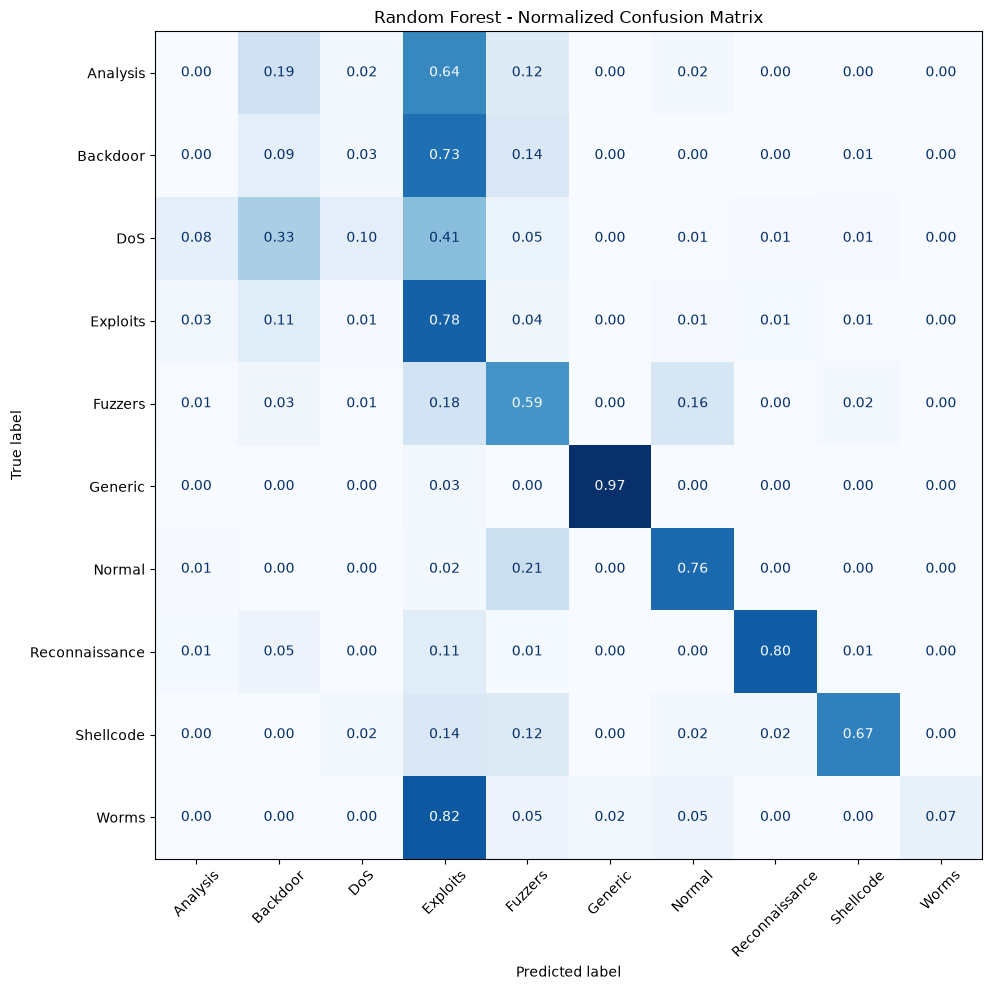

Random Forest confusion matrix saved successfully!


In [18]:
from pathlib import Path
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

classes = sorted(y_test.unique())

fig, ax = plt.subplots(figsize=(12, 10))

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred_rf,
    labels=classes,
    normalize="true",
    values_format=".2f",
    cmap="Blues",
    xticks_rotation=45,
    ax=ax,
    colorbar=False
)

ax.set_title("Random Forest - Normalized Confusion Matrix")

fig.tight_layout()

output_dir = Path("../results/figures")
output_dir.mkdir(parents=True, exist_ok=True)

fig.savefig(
    output_dir / "random_forest_confusion_matrix_normalized.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Random Forest confusion matrix saved successfully!")